# IE 7615 Project — Week 1: Single-Object Image ID (CNN Model Comparison)

Classify a single-object image into one of the class object IDs (OBJ001 … OBJ073) and compare five CNNs:

| Model | Type | Training strategy |
|---|---|---|
| Custom CNN | Built from scratch (baseline) | 5 Conv-BN-ReLU-MaxPool blocks, trained end-to-end |
| VGG16 | Transfer learning (ImageNet) | Stage 1 frozen backbone + new head → Stage 2 fine-tune `block5` |
| ResNet50 | Transfer learning (ImageNet) | Stage 1 → Stage 2 fine-tune `conv5` |
| MobileNetV2 | Transfer learning (ImageNet) | Stage 1 → Stage 2 fine-tune from `block_13` |
| EfficientNetB0 | Transfer learning (ImageNet) | Stage 1 → Stage 2 fine-tune from `block6a` |

**How to run on Google Colab**
1. Put `database.zip` in Google Drive at `My Drive/NEU/IE7615 Deep Learning for AI/Project1/database.zip`.
2. Open this notebook in Colab → *Runtime → Change runtime type → T4 GPU*.
3. *Runtime → Run all*, and allow Google Drive access when asked.

Results (models, metrics, plots) are saved to `My Drive/NEU/IE7615 Deep Learning for AI/Project1/week1_results/`.
If the runtime disconnects, run all again: models that already finished are skipped.

## 1. Setup

In [5]:
import os, re, sys, json, time, zipfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras   # Keras 3 top-level API (tensorflow.keras in TF >= 2.16 lacks keras.saving)
from keras import layers, models
from keras import applications as A
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, top_k_accuracy_score, confusion_matrix, classification_report
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
QUICK = os.environ.get("QUICK") == "1"   # local smoke test only: tiny subset, 1 epoch, no ImageNet weights

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/NEU/IE7615 Deep Learning for AI/Project1"
    if not os.path.isdir("/content/database"):
        with zipfile.ZipFile(f"{DRIVE_DIR}/database.zip") as z:   # unzip to local disk: much faster than reading from Drive
            z.extractall("/content")
    DATA_DIR = "/content/database"
    OUT_DIR = f"{DRIVE_DIR}/week1_results"
    CKPT_DIR = "/content/ckpt"
else:
    DATA_DIR = os.environ.get("DATA_DIR", "database")
    OUT_DIR = os.environ.get("OUT_DIR", "week1_results")
    CKPT_DIR = os.path.join(OUT_DIR, "ckpt")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

IMG_SIZE = 224
BATCH = 32
SEED = 42
HEAD_EPOCHS, FT_EPOCHS, CUSTOM_EPOCHS = (1, 1, 1) if QUICK else (15, 15, 60)
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__)
GPUS = tf.config.list_physical_devices("GPU")
print("GPU:", GPUS if GPUS else "NONE  <-- switch the runtime to T4 GPU, CPU training takes ~8 hours")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset

* One folder per object: `images_OBJxxx/`. The label is the folder name.
* `*_bg_*` files are empty background shots (kept for Week 2 multi-object composites), so they are **excluded** here.
* Stratified 70 / 15 / 15 train / validation / test split, fixed seed, identical for every model.

In [6]:
IMG_RE = re.compile(r"\.jpe?g$", re.I)
BG_RE = re.compile(r"_bg_", re.I)

class_dirs = sorted(d for d in os.listdir(DATA_DIR) if d.startswith("images_OBJ"))
if QUICK:
    class_dirs = class_dirs[:5]
class_names = [d.replace("images_", "") for d in class_dirs]
NUM_CLASSES = len(class_names)

paths, labels = [], []
for i, d in enumerate(class_dirs):
    files = sorted(f for f in os.listdir(os.path.join(DATA_DIR, d)) if IMG_RE.search(f) and not BG_RE.search(f))
    if QUICK:
        files = files[:20]
    paths += [os.path.join(DATA_DIR, d, f) for f in files]
    labels += [i] * len(files)
paths, labels = np.array(paths), np.array(labels)

p_train, p_tmp, y_train, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(f"{NUM_CLASSES} classes | {len(paths)} object images")
print(f"train {len(p_train)} | val {len(p_val)} | test {len(p_test)}")
counts = np.bincount(labels)
print(f"images per class: min {counts.min()}, max {counts.max()}, mean {counts.mean():.1f}")

pd.DataFrame({"path": [os.path.relpath(p, DATA_DIR) for p in np.concatenate([p_train, p_val, p_test])],
              "label": np.concatenate([y_train, y_val, y_test]),
              "split": ["train"] * len(p_train) + ["val"] * len(p_val) + ["test"] * len(p_test)}
             ).to_csv(f"{OUT_DIR}/split.csv", index=False)
json.dump(class_names, open(f"{OUT_DIR}/class_names.json", "w"))

73 classes | 6964 object images
train 4874 | val 1045 | test 1045
images per class: min 90, max 106, mean 95.4


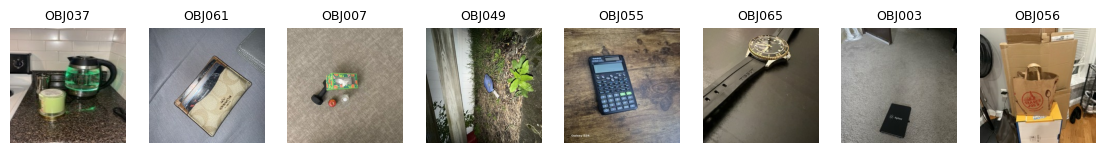

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))   # also fixes the few images that are not 224x224
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), label   # cache as uint8 to save RAM

def make_ds(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y)).map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(2000, seed=SEED)
    return ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, shuffle=True)
val_ds = make_ds(p_val, y_val)
test_ds = make_ds(p_test, y_test)

x, y = next(iter(train_ds))
plt.figure(figsize=(14, 3))
for i in range(min(8, len(y))):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(class_names[int(y[i])], fontsize=9)
    plt.axis("off")
plt.show()

## 3. Models

* **Data augmentation** (train only; inactive at inference): flip, rotation, zoom, shift, brightness, contrast.
  The dataset was shot under different lighting and angles, so the augmentation copies that variation.
* **Transfer learning** with two stages:
  1. *Feature extraction*: the ImageNet backbone is frozen; only the new Dropout + Dense(softmax) head is trained (lr 1e-3).
  2. *Fine-tuning*: the top block(s) of the backbone are unfrozen (BatchNorm stays frozen) and trained with lr 1e-4.
* Each backbone gets the input preprocessing it was pretrained with.
* The checkpoint with the best **validation accuracy** across both stages is kept.

In [8]:
def make_augment():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomBrightness(0.2),
        layers.RandomContrast(0.2),
    ], name="augmentation")


@keras.saving.register_keras_serializable(package="ie7615")
class CaffePreprocess(layers.Layer):
    # ResNet50 / VGG16 preprocessing: RGB [0,255] -> BGR minus the ImageNet channel means
    def call(self, x):
        return tf.reverse(x, axis=[-1]) - tf.constant([103.939, 116.779, 123.68])


BACKBONES = {
    # name: (constructor, preprocessing layer, first backbone layer unfrozen in stage 2)
    "MobileNetV2":    (A.MobileNetV2,    lambda: layers.Rescaling(1 / 127.5, offset=-1), "block_13_expand"),
    "EfficientNetB0": (A.EfficientNetB0, None,                                            "block6a_expand_conv"),  # rescales internally
    "ResNet50":       (A.ResNet50,       CaffePreprocess,                                 "conv5_block1_1_conv"),
    "VGG16":          (A.VGG16,          CaffePreprocess,                                 "block5_conv1"),
}


def build_transfer(name):
    ctor, pre, _ = BACKBONES[name]
    base = ctor(include_top=False, weights=None if QUICK else "imagenet",
                input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base.trainable = False
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inp)
    if pre:
        x = pre()(x)
    x = base(x, training=False)   # BatchNorm stays in inference mode, also while fine-tuning
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name=name), base


def build_custom():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inp)
    x = layers.Rescaling(1 / 255.0)(x)
    for filters in [32, 64, 128, 256, 512]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name="CustomCNN")

In [9]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])


class BestCheckpoint(keras.callbacks.Callback):
    # saves the model whenever val_accuracy improves; one instance spans both training stages
    def __init__(self, path):
        super().__init__()
        self.path, self.best = path, -1.0

    def on_epoch_end(self, epoch, logs=None):
        if logs["val_accuracy"] > self.best:
            self.best = logs["val_accuracy"]
            self.model.save(self.path)


def fit(model, epochs, patience, ckpt, extra_callbacks=()):
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=patience), ckpt, *extra_callbacks]
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2).history
    return {k: [float(v) for v in vals] for k, vals in h.items()}


def train(name):
    ckpt_path = f"{CKPT_DIR}/{name}.keras"
    ckpt = BestCheckpoint(ckpt_path)
    t0 = time.time()
    if name == "CustomCNN":
        model = build_custom()
        compile_model(model, 1e-3)
        hist = fit(model, CUSTOM_EPOCHS, 10, ckpt,
                   [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)])
        stage1_epochs = len(hist["loss"])
    else:
        model, base = build_transfer(name)
        # Stage 1: feature extraction
        compile_model(model, 1e-3)
        hist = fit(model, HEAD_EPOCHS, 4, ckpt)
        stage1_epochs = len(hist["loss"])
        # Stage 2: fine-tune the top of the backbone
        base.trainable = True
        unfreeze = False
        for layer in base.layers:
            unfreeze = unfreeze or layer.name == BACKBONES[name][2]
            layer.trainable = unfreeze and not isinstance(layer, layers.BatchNormalization)
        compile_model(model, 1e-4)
        h2 = fit(model, FT_EPOCHS, 4, ckpt)
        hist = {k: hist[k] + h2[k] for k in hist if k in h2}
    train_min = (time.time() - t0) / 60
    best = keras.models.load_model(ckpt_path)
    return best, ckpt_path, hist, stage1_epochs, train_min


def evaluate(model, name, ckpt_path, hist, stage1_epochs, train_min):
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    val_acc = model.evaluate(val_ds, verbose=0)[1]
    x1 = tf.zeros((1, IMG_SIZE, IMG_SIZE, 3))
    for _ in range(3):
        model(x1, training=False)
    t = time.time()
    for _ in range(20):
        model(x1, training=False)
    metrics = {
        "model": name,
        "val_acc": round(float(val_acc), 4),
        "test_acc": round(float((y_pred == y_test).mean()), 4),
        "test_top5": round(float(top_k_accuracy_score(y_test, probs, k=min(5, NUM_CLASSES - 1), labels=range(NUM_CLASSES))), 4),
        "test_macro_f1": round(float(f1_score(y_test, y_pred, average="macro")), 4),
        "params_M": round(model.count_params() / 1e6, 2),
        "size_MB": round(model.count_params() * 4 / 1e6, 1),   # float32 weights
        "epochs": len(hist["loss"]),
        "stage1_epochs": stage1_epochs,
        "train_min": round(train_min, 1),
        "latency_ms_per_img": round((time.time() - t) / 20 * 1000, 1),
    }
    return metrics, probs

## 4. Train and evaluate all models

Order: fastest first, so the most useful results are saved early. Each finished model is written to Drive right away.

In [10]:
ORDER = ["MobileNetV2", "EfficientNetB0", "ResNet50", "CustomCNN", "VGG16"]
results = {}

for name in ORDER:
    d = f"{OUT_DIR}/{name}"
    if os.path.exists(f"{d}/metrics.json"):
        print(f"{name}: already done, skipping")
        results[name] = json.load(open(f"{d}/metrics.json"))
        continue
    os.makedirs(d, exist_ok=True)
    print(f"\n========== {name} ==========")
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model, ckpt_path, hist, s1, train_min = train(name)
    metrics, probs = evaluate(model, name, ckpt_path, hist, s1, train_min)

    shutil.copy(ckpt_path, f"{d}/model.keras")
    np.save(f"{d}/test_probs.npy", probs)
    json.dump(hist, open(f"{d}/history.json", "w"))
    with open(f"{d}/summary.txt", "w") as f:
        model.summary(print_fn=lambda line, *a, **k: f.write(line + "\n"))
    json.dump(metrics, open(f"{d}/metrics.json", "w"), indent=1)   # written last = "done" marker
    results[name] = metrics
    print(metrics)


========== MobileNetV2 ==========
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
153/153 - 27s - 178ms/step - accuracy: 0.4116 - loss: 2.6563 - val_accuracy: 0.7732 - val_loss: 1.1195
Epoch 2/15
153/153 - 13s - 84ms/step - accuracy: 0.7567 - loss: 1.0372 - val_accuracy: 0.8431 - val_loss: 0.7311
Epoch 3/15
153/153 - 12s - 80ms/step - accuracy: 0.8346 - loss: 0.6868 - val_accuracy: 0.8632 - val_loss: 0.5886
Epoch 4/15
153/153 - 13s - 84ms/step - accuracy: 0.8650 - loss: 0.5506 - val_accuracy: 0.8842 - val_loss: 0.5014
Epoch 5/15
153/153 - 12s - 77ms/step - accuracy: 0.8859 - loss: 0.4623 - val_accuracy: 0.8813 - val_loss: 0.4660
Epoch 6/15
153/153 - 12s - 78ms/step - accuracy: 0.9005 - loss: 0.3952 - val_accuracy: 0.8794 - val_loss: 0.4553
Epoch 7/15
153/153 - 13s - 84ms/step - accuracy: 0.9122 - loss: 0.3532 - val_accuracy: 0.8947 - val_loss: 0.4086
Epoch 8/15
153/153 - 13s - 84ms/step - accuracy: 0.9192 - loss: 0.3054 - val_accuracy: 0.8967 - val_loss: 0.3778
Epoch 9/15


{'model': 'MobileNetV2', 'val_acc': 0.9617, 'test_acc': 0.9617, 'test_top5': 0.9933, 'test_macro_f1': 0.9619, 'params_M': 2.35, 'size_MB': 9.4, 'epochs': 29, 'stage1_epochs': 14, 'train_min': 7.1, 'latency_ms_per_img': 150.0}

========== EfficientNetB0 ==========
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
153/153 - 30s - 194ms/step - accuracy: 0.4795 - loss: 2.6975 - val_accuracy: 0.8211 - val_loss: 1.2450
Epoch 2/15
153/153 - 18s - 115ms/step - accuracy: 0.8076 - loss: 1.1283 - val_accuracy: 0.8708 - val_loss: 0.7227
Epoch 3/15
153/153 - 16s - 107ms/step - accuracy: 0.8683 - loss: 0.7373 - val_accuracy: 0.8938 - val_loss: 0.5485
Epoch 4/15
153/153 - 16s - 104ms/step - accuracy: 0.9001 - loss: 0.5590 - val_accuracy: 0.9091 - val_loss: 0.4513
Epoch 5/15
153/153 - 16s - 106ms/step - accuracy: 0.9165 - loss: 0.4564 - val_accuracy: 0.9148 - val_loss: 0.3865
Epoch 6/15
153/153 - 17s - 113ms/step - accuracy: 0.9302 - loss: 0.3785 - val_accuracy: 0.9330 - val_loss: 0.3418
E

{'model': 'EfficientNetB0', 'val_acc': 0.9818, 'test_acc': 0.9742, 'test_top5': 0.9971, 'test_macro_f1': 0.9743, 'params_M': 4.14, 'size_MB': 16.6, 'epochs': 30, 'stage1_epochs': 15, 'train_min': 9.9, 'latency_ms_per_img': 282.7}

========== ResNet50 ==========
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/15
153/153 - 43s - 278ms/step - accuracy: 0.4764 - loss: 2.3137 - val_accuracy: 0.8249 - val_loss: 0.7452
Epoch 2/15
153/153 - 30s - 195ms/step - accuracy: 0.8178 - loss: 0.7565 - val_accuracy: 0.8861 - val_loss: 0.4532
Epoch 3/15
153/153 - 30s - 198ms/step - accuracy: 0.8726 - loss: 0.5029 - val_accuracy: 0.9091 - val_loss: 0.3461
Epoch 4/15
153/153 - 32s - 208ms/step - accuracy: 0.9142 - loss: 0.3490 - val_accuracy: 0.9225 - val_loss: 0.2854
Epoch 5/15
153/153 - 30s - 197ms/step - accuracy: 0.9278 - loss: 0.2803 - val_accuracy: 0.9359 - val_loss: 0.2425
Epoch 6/15
153/153 - 30s - 199ms/step - accuracy: 0.9360 - loss: 0.2396 - val_accuracy: 0.9321 - val_loss: 0.2446
Epo

{'model': 'ResNet50', 'val_acc': 0.9751, 'test_acc': 0.9703, 'test_top5': 0.9962, 'test_macro_f1': 0.9702, 'params_M': 23.74, 'size_MB': 94.9, 'epochs': 28, 'stage1_epochs': 13, 'train_min': 16.5, 'latency_ms_per_img': 224.3}

========== CustomCNN ==========
Epoch 1/60
153/153 - 34s - 225ms/step - accuracy: 0.0823 - loss: 4.0828 - val_accuracy: 0.0153 - val_loss: 5.1596 - learning_rate: 0.0010
Epoch 2/60
153/153 - 25s - 163ms/step - accuracy: 0.1475 - loss: 3.5343 - val_accuracy: 0.0469 - val_loss: 4.5842 - learning_rate: 0.0010
Epoch 3/60
153/153 - 41s - 270ms/step - accuracy: 0.2142 - loss: 3.1933 - val_accuracy: 0.1789 - val_loss: 3.4560 - learning_rate: 0.0010
Epoch 4/60
153/153 - 26s - 172ms/step - accuracy: 0.2614 - loss: 2.9410 - val_accuracy: 0.2038 - val_loss: 3.4628 - learning_rate: 0.0010
Epoch 5/60
153/153 - 24s - 157ms/step - accuracy: 0.3110 - loss: 2.7305 - val_accuracy: 0.2316 - val_loss: 3.4594 - learning_rate: 0.0010
Epoch 6/60
153/153 - 24s - 156ms/step - accuracy: 0

{'model': 'CustomCNN', 'val_acc': 0.7703, 'test_acc': 0.7847, 'test_top5': 0.9263, 'test_macro_f1': 0.7852, 'params_M': 1.61, 'size_MB': 6.4, 'epochs': 55, 'stage1_epochs': 55, 'train_min': 23.2, 'latency_ms_per_img': 22.6}

========== VGG16 ==========
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/15
153/153 - 40s - 260ms/step - accuracy: 0.1321 - loss: 6.7497 - val_accuracy: 0.4986 - val_loss: 2.5517
Epoch 2/15
153/153 - 33s - 217ms/step - accuracy: 0.4216 - loss: 3.0131 - val_accuracy: 0.7033 - val_loss: 1.4359
Epoch 3/15
153/153 - 34s - 220ms/step - accuracy: 0.5683 - loss: 2.0064 - val_accuracy: 0.7914 - val_loss: 0.9620
Epoch 4/15
153/153 - 34s - 223ms/step - accuracy: 0.6586 - loss: 1.4811 - val_accuracy: 0.8220 - val_loss: 0.8004
Epoch 5/15
153/153 - 34s - 220ms/step - accuracy: 0.7204 - loss: 1.1877 - val_accuracy: 0.8507 - val_loss: 0.6278
Epoch 6/15
153/153 - 34s - 222ms/step - accuracy: 0.7483 - loss: 0.9982 - val_accuracy: 0.8536 - val_loss: 0.6160
Epoch 7/15
1

{'model': 'VGG16', 'val_acc': 0.955, 'test_acc': 0.9502, 'test_top5': 0.9866, 'test_macro_f1': 0.95, 'params_M': 14.75, 'size_MB': 59.0, 'epochs': 23, 'stage1_epochs': 15, 'train_min': 13.8, 'latency_ms_per_img': 28.7}


## 5. Comparison

,model,val_acc,test_acc,test_top5,test_macro_f1,params_M,size_MB,epochs,stage1_epochs,train_min,latency_ms_per_img
0,EfficientNetB0,0.9818,0.9742,0.9971,0.9743,4.14,16.6,30,15,9.9,282.7
1,ResNet50,0.9751,0.9703,0.9962,0.9702,23.74,94.9,28,13,16.5,224.3
2,MobileNetV2,0.9617,0.9617,0.9933,0.9619,2.35,9.4,29,14,7.1,150.0
3,VGG16,0.9550,0.9502,0.9866,0.9500,14.75,59.0,23,15,13.8,28.7
4,CustomCNN,0.7703,0.7847,0.9263,0.7852,1.61,6.4,55,55,23.2,22.6


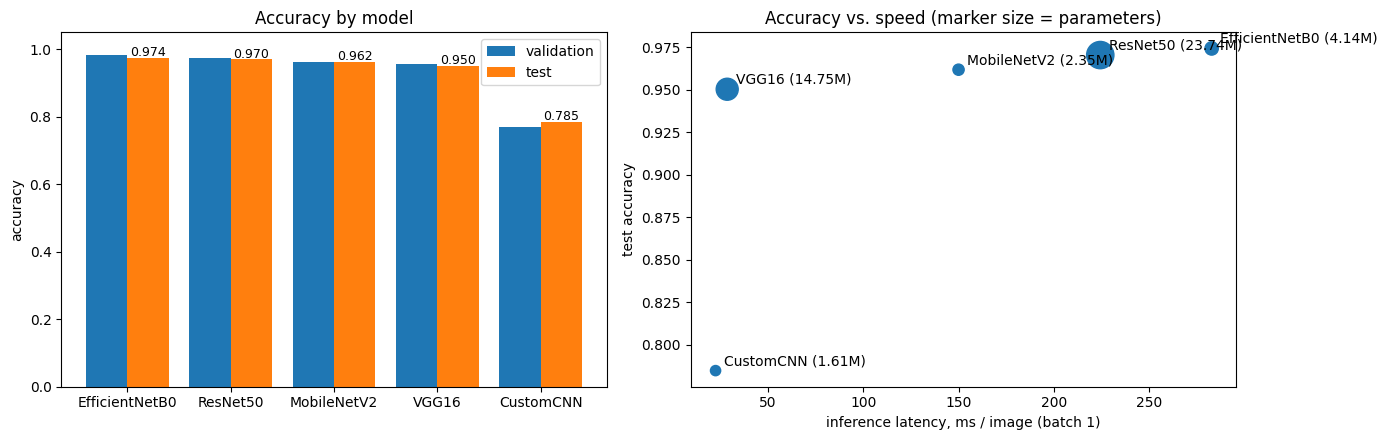

In [11]:
df = pd.DataFrame([results[n] for n in ORDER if n in results]).sort_values("val_acc", ascending=False).reset_index(drop=True)
df.to_csv(f"{OUT_DIR}/model_comparison.csv", index=False)
display(df)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(df))
ax[0].bar(x - 0.2, df.val_acc, 0.4, label="validation")
ax[0].bar(x + 0.2, df.test_acc, 0.4, label="test")
for i, v in enumerate(df.test_acc):
    ax[0].text(i + 0.2, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
ax[0].set_xticks(x); ax[0].set_xticklabels(df.model); ax[0].set_ylim(0, 1.05)
ax[0].set_ylabel("accuracy"); ax[0].set_title("Accuracy by model"); ax[0].legend()
ax[1].scatter(df.latency_ms_per_img, df.test_acc, s=df.params_M * 15 + 30)
for _, r in df.iterrows():
    ax[1].annotate(f"{r.model} ({r.params_M}M)", (r.latency_ms_per_img, r.test_acc), textcoords="offset points", xytext=(6, 4))
ax[1].set_xlabel("inference latency, ms / image (batch 1)"); ax[1].set_ylabel("test accuracy")
ax[1].set_title("Accuracy vs. speed (marker size = parameters)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/accuracy_comparison.png", dpi=150); plt.show()

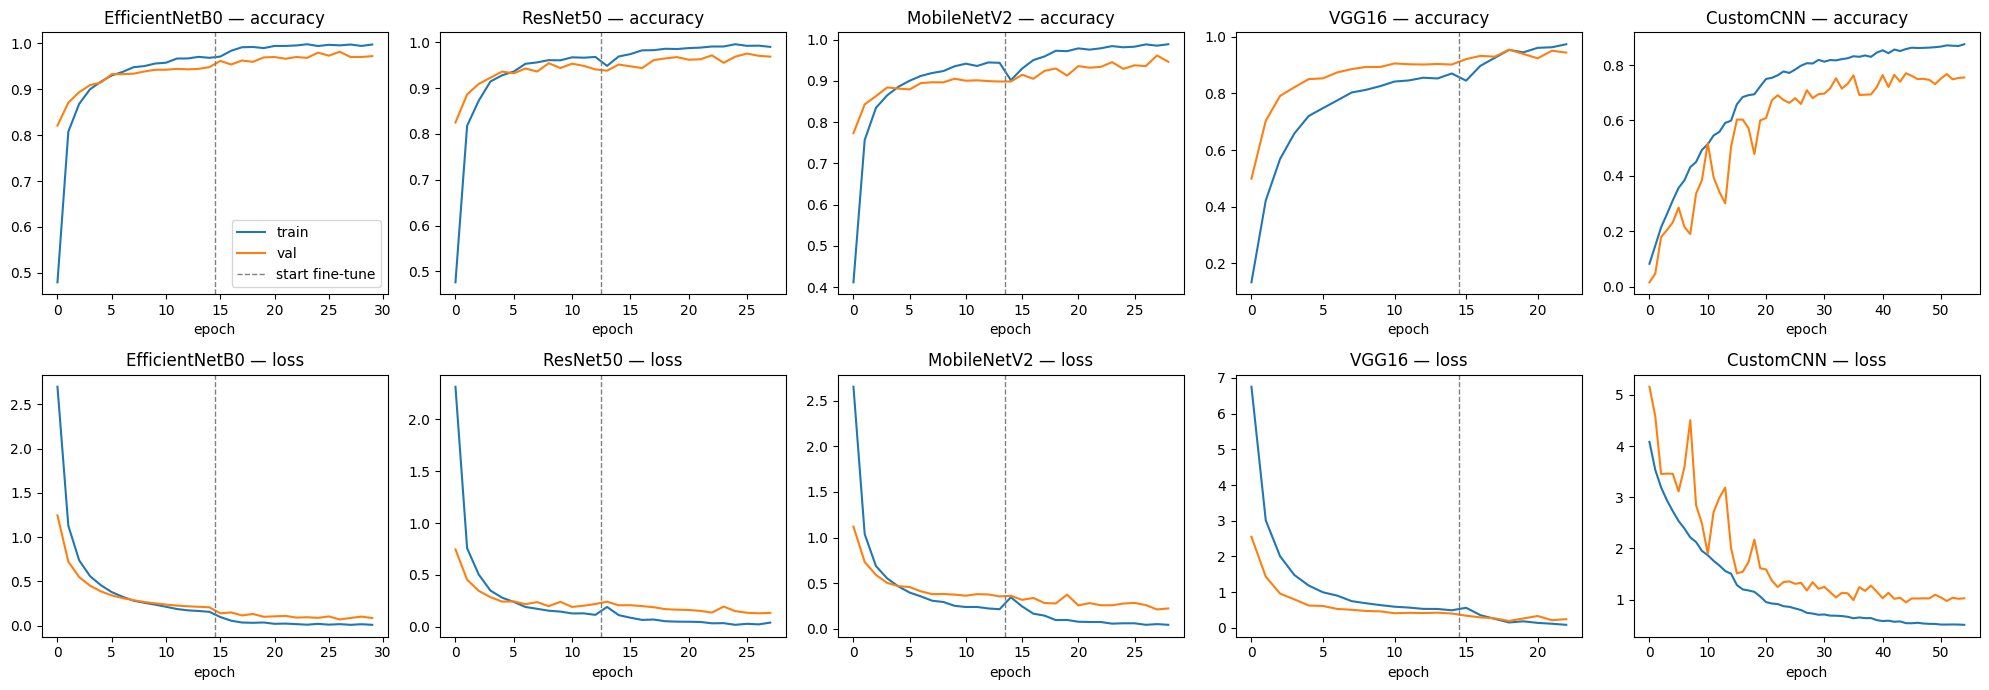

In [12]:
names = list(df.model)
fig, axes = plt.subplots(2, len(names), figsize=(4 * len(names), 7), squeeze=False)
for j, name in enumerate(names):
    h = json.load(open(f"{OUT_DIR}/{name}/history.json"))
    s1 = results[name]["stage1_epochs"]
    for i, (k, title) in enumerate([("accuracy", "accuracy"), ("loss", "loss")]):
        a = axes[i, j]
        a.plot(h[k], label="train"); a.plot(h["val_" + k], label="val")
        if name != "CustomCNN":
            a.axvline(s1 - 0.5, color="gray", ls="--", lw=1, label="start fine-tune")
        a.set_title(f"{name} — {title}"); a.set_xlabel("epoch")
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learning_curves.png", dpi=150); plt.show()

## 6. Best model: error analysis

The best model is selected by **validation** accuracy (the test set is only used for reporting).

Best model: EfficientNetB0 | test accuracy 0.9742


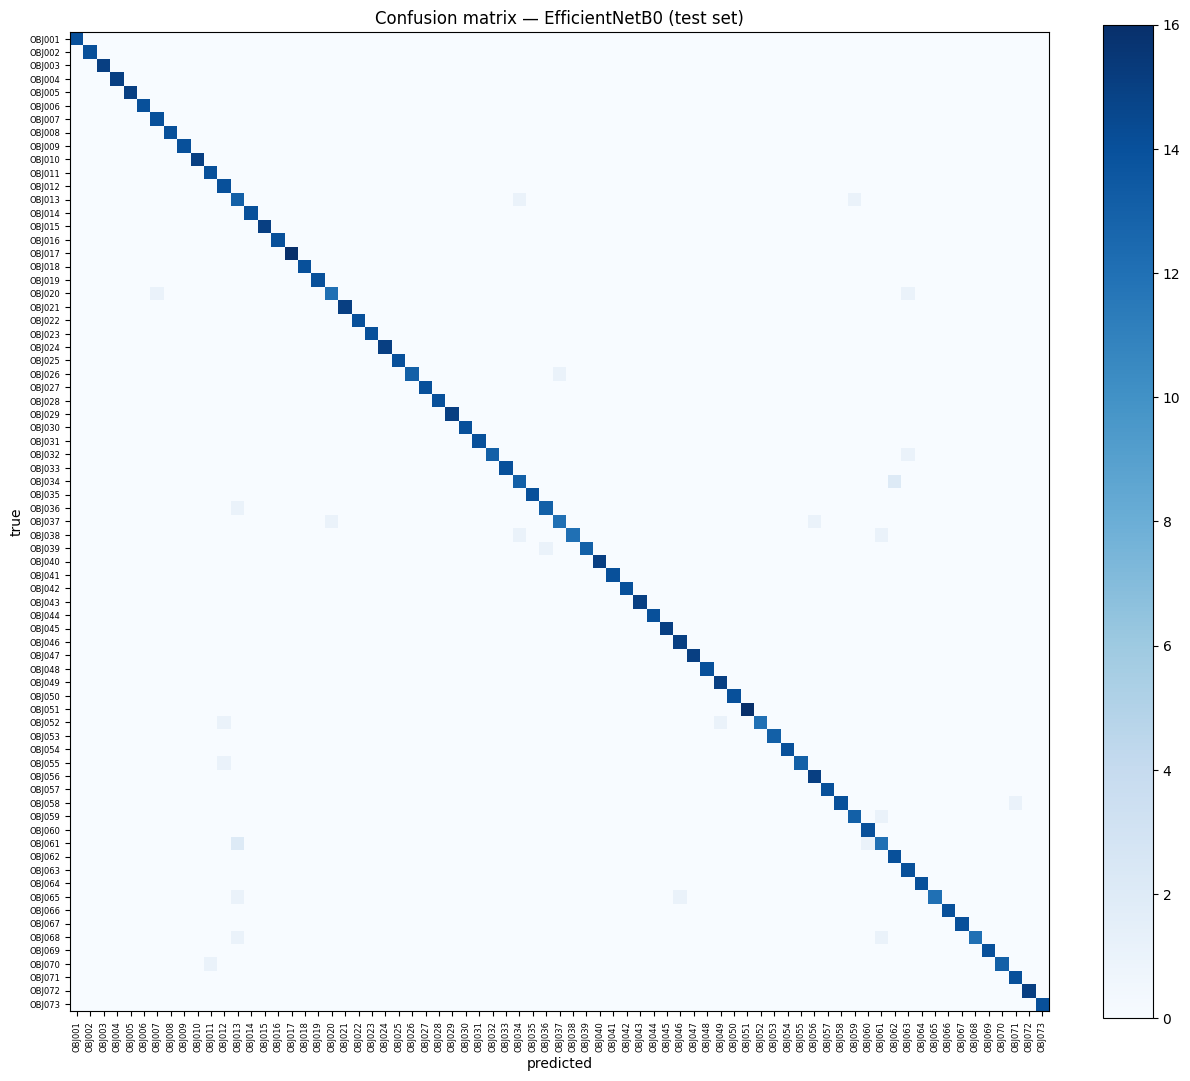

Lowest-recall classes:


,precision,recall,f1-score,support
OBJ061,0.800000,0.800000,0.800000,15.0
OBJ020,0.923077,0.857143,0.888889,14.0
OBJ038,1.000000,0.857143,0.923077,14.0
OBJ052,1.000000,0.857143,0.923077,14.0
OBJ037,0.923077,0.857143,0.888889,14.0
OBJ065,1.000000,0.857143,0.923077,14.0
OBJ068,1.000000,0.857143,0.923077,14.0
OBJ013,0.722222,0.866667,0.787879,15.0
OBJ034,0.866667,0.866667,0.866667,15.0
OBJ039,1.000000,0.928571,0.962963,14.0


Most confused pairs (true -> predicted, count):


,true,predicted,count
0,OBJ061,OBJ013,2
1,OBJ034,OBJ062,2
2,OBJ059,OBJ061,1
3,OBJ065,OBJ013,1
4,OBJ065,OBJ046,1
5,OBJ070,OBJ011,1
6,OBJ068,OBJ061,1
7,OBJ039,OBJ036,1
8,OBJ013,OBJ059,1
9,OBJ037,OBJ056,1


In [13]:
BEST = df.model[0]
shutil.copy(f"{OUT_DIR}/{BEST}/model.keras", f"{OUT_DIR}/best_model.keras")
probs = np.load(f"{OUT_DIR}/{BEST}/test_probs.npy")
y_pred = probs.argmax(1)
print(f"Best model: {BEST} | test accuracy {(y_pred == y_test).mean():.4f}")

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
plt.figure(figsize=(12, 11))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(NUM_CLASSES), class_names, rotation=90, fontsize=6)
plt.yticks(range(NUM_CLASSES), class_names, fontsize=6)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"Confusion matrix — {BEST} (test set)")
plt.colorbar(fraction=0.046)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix_best.png", dpi=150); plt.show()

report = pd.DataFrame(classification_report(y_test, y_pred, labels=range(NUM_CLASSES), target_names=class_names,
                                            output_dict=True, zero_division=0)).T
report.to_csv(f"{OUT_DIR}/per_class_report_best.csv")
print("Lowest-recall classes:")
display(report.iloc[:NUM_CLASSES].sort_values("recall").head(10))

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(class_names[i], class_names[j], off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1], off.shape)) if off[i, j] > 0][:10]
print("Most confused pairs (true -> predicted, count):")
display(pd.DataFrame(pairs, columns=["true", "predicted", "count"]))

27 misclassified test images out of 1045


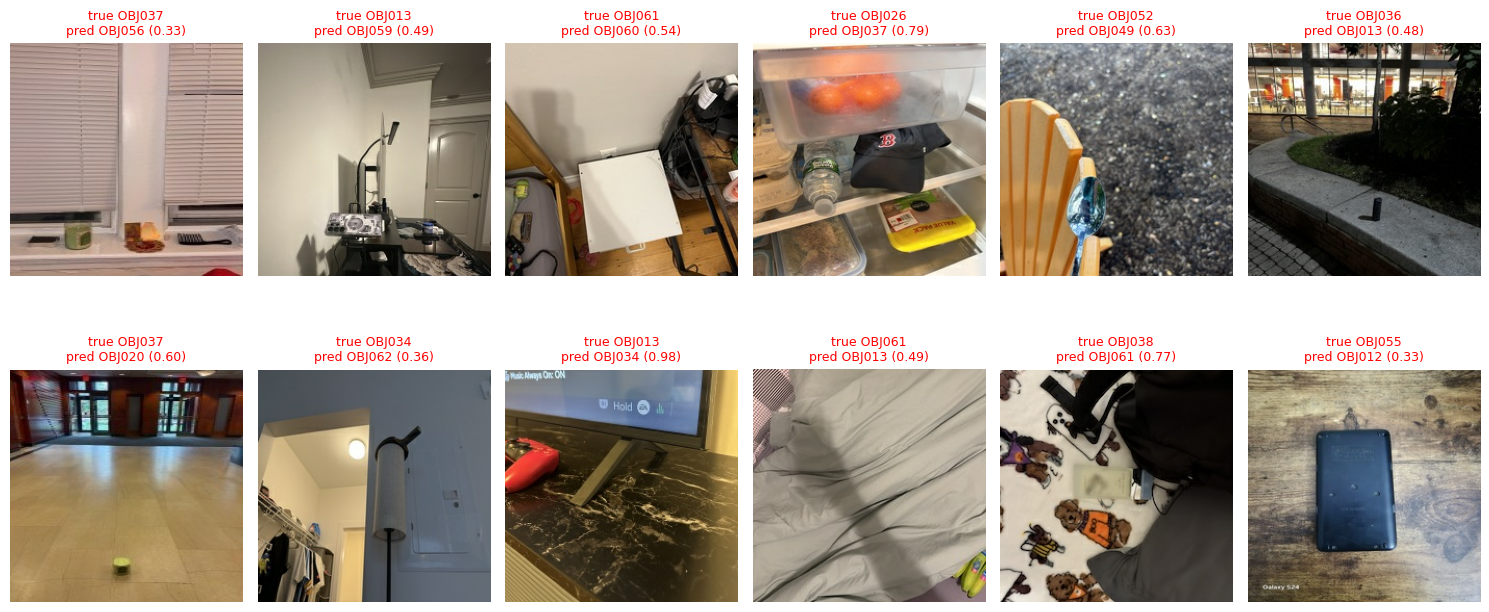

In [14]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} misclassified test images out of {len(y_test)}")
n = min(12, len(wrong))
if n:
    plt.figure(figsize=(15, 3.6 * ((n + 5) // 6)))
    for k, i in enumerate(wrong[:n]):
        plt.subplot((n + 5) // 6, 6, k + 1)
        img = load_image(p_test[i], 0)[0].numpy()
        plt.imshow(img)
        plt.title(f"true {class_names[y_test[i]]}\npred {class_names[y_pred[i]]} ({probs[i].max():.2f})", fontsize=9, color="red")
        plt.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/misclassified_best.png", dpi=120); plt.show()

## 7. Demo: identify OBJ036

The demo uses only OBJ036 images from the **test split**, which the model never saw during training.
For a live demo, take a new photo of OBJ036 (JPG) and run the last cell.

In [ ]:
from PIL import Image, ImageOps

best_model = keras.models.load_model(f"{OUT_DIR}/best_model.keras")

def load_photo(path):
    # new phone photos: apply the EXIF rotation, center-crop to a square, resize to 224x224
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    s = min(im.size)
    left, top = (im.width - s) // 2, (im.height - s) // 2
    return np.asarray(im.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE)))

def predict_image(path, model=best_model, top=3, new_photo=False):
    img = load_photo(path) if new_photo else load_image(path, 0)[0].numpy()
    p = model.predict(img[None].astype("float32"), verbose=0)[0]
    order = p.argsort()[::-1][:top]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[order[0]]}  ({p[order[0]]:.1%})"); plt.show()
    return [(class_names[i], round(float(p[i]), 4)) for i in order]

In [ ]:
DEMO_ID = "OBJ036"
demo_label = class_names.index(DEMO_ID)
demo_paths = p_test[y_test == demo_label]   # test split only: never seen in training

x = np.stack([load_image(p, 0)[0].numpy() for p in demo_paths]).astype("float32")
demo_probs = best_model.predict(x, verbose=0)
demo_pred = demo_probs.argmax(1)
print(f"{BEST}: {int((demo_pred == demo_label).sum())} / {len(demo_paths)} unseen {DEMO_ID} test images identified correctly")

cols = 7
rows = -(-len(demo_paths) // cols)
plt.figure(figsize=(2.4 * cols, 2.8 * rows))
for k in range(len(demo_paths)):
    ok = demo_pred[k] == demo_label
    plt.subplot(rows, cols, k + 1)
    plt.imshow(x[k].astype("uint8")); plt.axis("off")
    plt.title(f"{'✓' if ok else '✗'} {class_names[demo_pred[k]]} ({demo_probs[k].max():.0%})",
              fontsize=9, color="#006300" if ok else "#d03b3b")
plt.suptitle(f"{DEMO_ID}: predictions on unseen test images", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/demo_{DEMO_ID}.png", dpi=120, bbox_inches="tight"); plt.show()

In [ ]:
# one test image of OBJ036 with its top-3 predictions (try indices 0 to len(demo_paths) - 1)
predict_image(demo_paths[0])

# live demo with a new photo: uncomment, run, and upload a JPG of OBJ036
# (iPhone: Settings > Camera > Formats > Most Compatible, so photos are JPG instead of HEIC)
# from google.colab import files
# uploaded = files.upload()
# predict_image(list(uploaded)[0], new_photo=True)